# Ablação do procedimento de seleção

Este notebook mede o **próprio procedimento** da AutoHybTS (§30.5 da especificação): quatro maneiras de escolher o modelo final, com **o mesmo orçamento de busca** e **os mesmos testes externos**.

| Procedimento | O que faz |
|---|---|
| `lowest_error` | a finalista de menor erro em `V_select`, sem limiares |
| `incremental` | a cadeia incremental guardada (ganho ≥ 1%, vitórias ≥ 60%, variabilidade), todas as famílias |
| `incremental_simple` | a mesma cadeia, só estruturas com até 2 modelos (individual e híbrido aditivo) |
| `guarded_nested` | como `incremental`; se a CV aninhada (com as mesmas famílias) disser que o procedimento não supera "a melhor base da seleção interna", fica a melhor base |

As séries são sintéticas e diárias, com previsibilidade do resíduo em três níveis (estratos): AR(0) (nada a corrigir), AR(0,5) e AR(0,8). Cada série guarda os últimos 14 pontos como teste externo selado. Além da melhor base escolhida em `V_select`, cada linha traz o erro externo de `naive` e `seasonal_naive` como referências simples.

O orçamento limita só o **número de candidatas** (sem relógio), então a execução é reprodutível em outra máquina. O custo de cada procedimento inclui tudo o que ele roda: busca, seleção e, no `guarded_nested`, as buscas internas da CV aninhada.

> O teste externo serve **só para relatar**. Não escolha o procedimento "vencedor" com ele: isso repetiria o erro que a ablação quer medir.

Este notebook é pesado (dezenas de minutos) e é versionado **com as saídas**.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts.benchmarks import (
    PROCEDURES,
    ablation_protocol,
    ablation_report,
    ablation_uncertainty,
    run_ablation,
    synthetic_cases,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## Perguntas

1. **Pioras:** a seleção guardada (`incremental`, `guarded_nested`) é pior que a melhor base em menos casos que `lowest_error`?
2. **Ganhos úteis:** quando o resíduo é previsível (AR(0,8)), os procedimentos guardados ainda escolhem o híbrido e ganham da base?
3. **Complexidade:** quanto da complexidade (híbridos, modelos ajustados) cada procedimento aceita quando não há o que aprender (AR(0))?
4. **Custo:** quanto custa cada procedimento, contando a CV aninhada?

As respostas valem só para estas séries, este horizonte e este orçamento.

## 1. Configuração

In [2]:
N_SERIES = 12
SEEDS = (0, 1, 2)
BUDGET = "small"  # 50 candidatas: a busca deixa de parar pelo limite total

cases = list(synthetic_cases(N_SERIES))
protocol = ablation_protocol(cases, SEEDS, BUDGET)
print("orçamento:", protocol["budget"])
pd.DataFrame(protocol["series"])

orçamento: {'preset': 'small', 'guard': {'max_trials_total': 50, 'max_trials_per_family': 15, 'max_candidates_per_stage': 25, 'max_refinements': 2}}


,series_id,length,horizon,test_size,seasonal_period,stratum
0,syn0-phi0.0,400,14,14,7,phi=0.0
1,syn1-phi0.5,400,14,14,7,phi=0.5
2,syn2-phi0.8,400,14,14,7,phi=0.8
3,syn3-phi0.0,400,14,14,7,phi=0.0
4,syn4-phi0.5,400,14,14,7,phi=0.5
5,syn5-phi0.8,400,14,14,7,phi=0.8
6,syn6-phi0.0,400,14,14,7,phi=0.0
7,syn7-phi0.5,400,14,14,7,phi=0.5
8,syn8-phi0.8,400,14,14,7,phi=0.8
9,syn9-phi0.0,400,14,14,7,phi=0.0


## 2. Execução

Para cada série e semente: uma busca com todas as famílias (serve a `lowest_error`, `incremental` e `guarded_nested`), uma busca restrita (`incremental_simple`) e a CV aninhada (`guarded_nested`). Cada candidata é avaliada **uma única vez** no teste externo.

In [3]:
started = time.perf_counter()
table = run_ablation(cases, seeds=SEEDS, budget=BUDGET)
print(f"{len(table)} linhas em {(time.perf_counter() - started) / 60:.1f} min")
print("paradas da busca:", table["stop_reason"].value_counts().to_dict())
print(
    "podas por limite:",
    table.drop_duplicates(["series_id", "seed", "search"])["pruned_by"].value_counts().to_dict(),
)
table[["series_id", "seed", "procedure", "champion", "test_score", "gain_vs_base"]].head(8)

144 linhas em 55.5 min
paradas da busca: {'budget_limited': 108, 'completed': 36}
podas por limite: {'max_trials_per_family:6': 36, '': 36}


,series_id,seed,procedure,champion,test_score,gain_vs_base
0,syn0-phi0.0,0,lowest_error,stl(linear-linear),1.020015,0.06656
1,syn0-phi0.0,0,incremental,seasonal_naive,1.038440,0.04970
2,syn0-phi0.0,0,incremental_simple,seasonal_naive,1.038440,0.04970
3,syn0-phi0.0,0,guarded_nested,knn,1.092749,0.00000
4,syn0-phi0.0,1,lowest_error,stl(linear-linear),1.020015,0.06656
5,syn0-phi0.0,1,incremental,knn,1.092749,0.00000
6,syn0-phi0.0,1,incremental_simple,knn,1.092749,0.00000
7,syn0-phi0.0,1,guarded_nested,knn,1.092749,0.00000


## 3. Resumo por procedimento

* `median_gain_vs_base`: ganho mediano no teste contra a melhor base individual de `V_select` (positivo = melhor).
* `beats_base_share`, `ties_base_share`, `worse_than_base_share`: frações de casos melhores, iguais e piores que essa base.
* `hybrid_share` e `mean_complexity`: fração de híbridos escolhidos e número médio de modelos ajustados na estrutura.
* `mean_gap`: erro no teste menos erro em `V_select` (positivo = a validação foi otimista).
* `mean_rank`: posto médio no teste entre os 4 procedimentos (menor = melhor).
* `mean_seconds`, `candidates`, `units`: custo médio do procedimento (sem o reajuste final nem a leitura do teste).
* `seed_std_of_median_gain`: quanto o ganho mediano varia entre sementes.

In [4]:
report = ablation_report(table)
report.round(4)

,median_gain_vs_base,beats_base_share,ties_base_share,worse_than_base_share,hybrid_share,mean_complexity,mean_gap,mean_rank,coverage,mean_seconds,candidates,units,seed_std_of_median_gain
procedure,,,,,,,,,,,,,
lowest_error,0.0,0.4444,0.4722,0.0833,0.5278,1.6389,0.0242,2.2083,1.0,33.5194,41.0,96.0,0.0166
incremental,0.0,0.2778,0.6944,0.0278,0.1389,1.1667,0.0449,2.4306,1.0,33.5194,41.0,96.0,0.0000
incremental_simple,0.0,0.1944,0.7778,0.0278,0.0556,1.0556,0.0592,2.6944,1.0,4.7099,17.0,44.0,0.0000
guarded_nested,0.0,0.1389,0.8611,0.0000,0.1111,1.1389,0.0635,2.6667,1.0,87.6326,123.0,288.0,0.0000


### Incerteza

As sementes de uma série não são independentes: o ganho de cada série é resumido (mediana entre sementes) e o intervalo de 95% reamostra **séries**.

In [5]:
ablation_uncertainty(table).round(4)

,n_series,median_gain_vs_base,ci_low,ci_high,better_share,worse_share
procedure,,,,,,
lowest_error,12,0.0235,0.0,0.0791,0.5000,0.0833
incremental,12,0.0000,0.0,0.0000,0.1667,0.0000
incremental_simple,12,0.0000,0.0,0.0000,0.1667,0.0000
guarded_nested,12,0.0000,0.0,0.0000,0.0833,0.0000


## 4. Por nível de previsibilidade do resíduo

Quando o resíduo é ruído branco (AR(0)), um híbrido não tem o que aprender: o bom procedimento deveria ficar com a base. Com AR(0,8), há o que corrigir.

In [6]:
by_stratum = ablation_report(table, by="stratum")
columns = ["median_gain_vs_base", "beats_base_share", "worse_than_base_share", "hybrid_share"]
by_stratum[columns].round(3)

median_gain_vs_base  beats_base_share  worse_than_base_share  hybrid_share
stratum procedure                                                                                     
phi=0.0 lowest_error                      0.067             0.667                  0.250         0.917
        incremental                       0.000             0.333                  0.083         0.250
        incremental_simple                0.000             0.250                  0.083         0.167
        guarded_nested                    0.000             0.167                  0.000         0.167
phi=0.5 lowest_error                      0.000             0.250                  0.000         0.250
        incremental                       0.000             0.333                  0.000         0.083
        incremental_simple                0.000             0.250                  0.000         0.000
        guarded_nested                    0.000             0.083                  0.000         0.083
phi=0.8 lowest_error                      0.000             0.417                  0.000         0.417
        incremental                       0.000             0.167                  0.000         0.083
        incremental_simple                0.000             0.083                  0.000         0.000
        guarded_nested                    0.000             0.167                  0.000         0.083

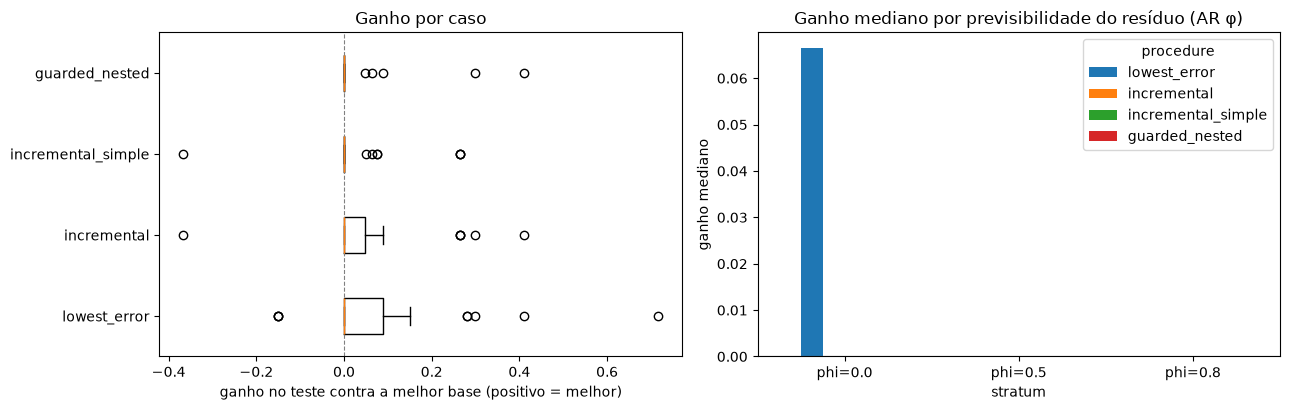

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
order = list(PROCEDURES)
axes[0].boxplot(
    [table.loc[table["procedure"] == p, "gain_vs_base"] for p in order],
    orientation="horizontal",
    tick_labels=order,
)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("ganho no teste contra a melhor base (positivo = melhor)")
axes[0].set_title("Ganho por caso")
gain_stratum = table.pivot_table(
    index="stratum", columns="procedure", values="gain_vs_base", aggfunc="median"
)
gain_stratum[order].plot(kind="bar", ax=axes[1], rot=0)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("ganho mediano")
axes[1].set_title("Ganho mediano por previsibilidade do resíduo (AR φ)")
fig.tight_layout()

## 5. Otimismo da validação

Lacuna = erro no teste − erro em `V_select`. Um procedimento que escolhe pelo menor erro tende a pegar a candidata que teve sorte na validação; a lacuna mostra quanto disso aparece no teste.

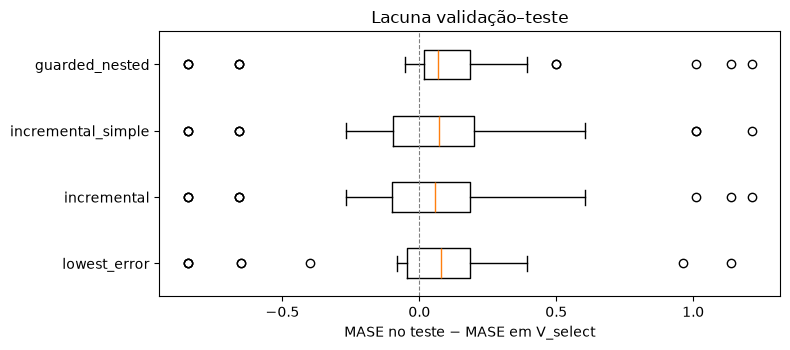

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot(
    [table.loc[table["procedure"] == p, "gap"] for p in order],
    orientation="horizontal",
    tick_labels=order,
)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("MASE no teste − MASE em V_select")
ax.set_title("Lacuna validação–teste")
fig.tight_layout()

## 6. Custo

Segundos por fase (média por caso) e trabalho feito. `lowest_error`, `incremental` e `guarded_nested` compartilham a mesma busca (coluna `search`): o custo de busca deles é o mesmo trabalho, não três medidas. O `guarded_nested` soma as buscas internas da CV aninhada (`nested_candidates`). `seconds_refit` (reajuste do escolhido antes do teste) e `seconds_external` (leitura do teste) são relato, não custo do procedimento.

In [9]:
cost_columns = [
    "seconds",
    "seconds_search",
    "seconds_selection",
    "seconds_nested",
    "seconds_refit",
    "seconds_external",
    "candidates",
    "search_candidates",
    "nested_candidates",
    "pruned_candidates",
    "units",
    "max_trials_total",
]
table.groupby("procedure")[cost_columns].mean().loc[order].round(2)

,seconds,seconds_search,seconds_selection,seconds_nested,seconds_refit,seconds_external,candidates,search_candidates,nested_candidates,pruned_candidates,units,max_trials_total
procedure,,,,,,,,,,,,
lowest_error,33.52,30.71,2.81,0.00,0.10,0.01,41.0,41.0,0.0,6.0,96.0,50.0
incremental,33.52,30.71,2.81,0.00,0.05,0.01,41.0,41.0,0.0,6.0,96.0,50.0
incremental_simple,4.71,4.13,0.58,0.00,0.02,0.01,17.0,17.0,0.0,0.0,44.0,50.0
guarded_nested,87.63,30.71,2.81,54.11,0.04,0.01,123.0,41.0,82.0,6.0,288.0,50.0


## 7. Estruturas escolhidas e referências simples

In [10]:
chosen = table.groupby("procedure")["champion"].value_counts().unstack(fill_value=0).T
references = table.drop_duplicates(["series_id", "seed"])[
    ["best_base_test", "naive_test", "seasonal_naive_test"]
].median()
print("MASE mediana no teste das referências:", references.round(3).to_dict())
chosen

MASE mediana no teste das referências: {'best_base_test': 0.89, 'naive_test': 1.602, 'seasonal_naive_test': 1.025}


procedure,guarded_nested,incremental,incremental_simple,lowest_error
champion,,,,
"comb(linear,mlp)",0,0,0,1
knn,6,2,2,3
linear,21,22,24,9
"linear-comb(knn,linear)",0,0,0,1
"linear-comb(linear,knn)",0,0,0,1
linear-knn,0,0,0,3
linear-linear,0,0,2,2
ma(linear-knn),2,3,0,3
ma(linear-linear),0,0,0,1


## 8. Tabela e protocolo

A tabela completa (uma linha por série, semente e procedimento) e o protocolo resolvido vão para `artifacts/ablation/` (fora do git). Para repetir pela linha de comando: `python -m autohybts.benchmarks.ablation --dataset synthetic --series 12 --seeds 0 1 2 --budget small --out ablation.csv`.

In [11]:
import json
from pathlib import Path

folder = Path("artifacts") / "ablation"
folder.mkdir(parents=True, exist_ok=True)
table.to_csv(folder / "ablation.csv", index=False)
(folder / "ablation.protocol.json").write_text(
    json.dumps(protocol, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print(sorted(p.name for p in folder.iterdir()))

['ablation.csv', 'ablation.protocol.json']


## 9. Leitura dos resultados

Nesta execução (12 séries × 3 sementes, orçamento `small`, esquema `ablation/2`, 55 min). Nenhuma busca parou pelo limite total; as buscas com todas as famílias tiveram 6 propostas podadas pelo limite por família, e a busca restrita completou.

1. **Pioras.** Contra a melhor base de `V_select`, `lowest_error` é pior em 8% dos casos; `incremental` e `incremental_simple` em 3%; `guarded_nested` em nenhum.
2. **Ganhos úteis.** `lowest_error` supera a base em 44% dos casos (mediana por série de +2,4%, IC 95% de 0 a 7,9%). Os procedimentos guardados superam em 14–28% e têm ganho mediano 0. No estrato AR(0,8) eles escolhem híbrido em só 0–8% dos casos e superam a base em 8–17%, contra 42% do `lowest_error`: a guarda recusa a maior parte do ganho disponível.
3. **Complexidade.** No estrato AR(0), `lowest_error` escolhe estrutura com corretor ou decomposição em 92% dos casos e supera a base em 67% deles: mesmo sem ruído AR, a base não captura toda a tendência e a sazonalidade, e estruturas como `stl(linear-linear)` ajudam. "Nada a corrigir" vale para o ruído, não para a forma do sinal. Os guardados ficam em 17–25% de híbridos nesse estrato.
4. **Custo.** Por caso: `incremental` 34 s e 41 candidatas; `incremental_simple` 5 s e 17; `guarded_nested` 88 s e 123 (82 delas na CV aninhada).

A **lacuna validação–teste** é positiva em todos e maior nos guardados. As referências simples ficam atrás da melhor base: MASE mediana 0,89 (melhor base), 1,03 (`seasonal_naive`) e 1,60 (`naive`).

Em relação à execução com `smoke` (mesmas séries e sementes), a busca maior aproximou `lowest_error` de um ganho real (mediana por série de 0 para +2,4%) e reduziu os híbridos do `incremental` (25% → 14%). Parte disso pode vir só do orçamento: não atribua a diferença a uma única mudança.

Limites: séries sintéticas, um horizonte, 2 dobras externas e um orçamento. A escolha entre aceitar mais ganhos (`lowest_error`) ou evitar pioras (guardados) depende de qual erro é mais caro; o notebook 11 mede o mesmo compromisso em controles com resposta conhecida. Não escolha o procedimento pelo teste externo.